In [23]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

BASE_URL = "https://breedhealthscore.com"
catalog_resp = requests.get(f"{BASE_URL}/api/breeds.json")
catalog_data = catalog_resp.json()

df_breeds = pd.DataFrame(catalog_data["breeds"])

df_exploded = df_breeds.explode("conditions")

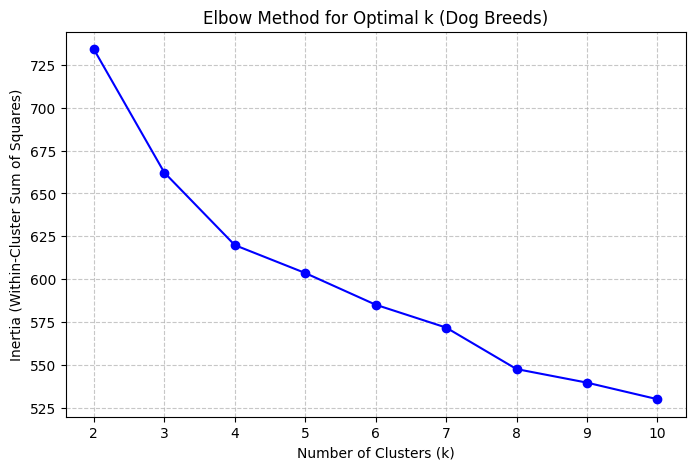

In [25]:
condition_matrix = pd.crosstab(df_exploded['slug'], df_exploded['conditions'])

lifespan_df = df_breeds[['slug', 'median_lifespan_years']].set_index('slug')
X = condition_matrix.join(lifespan_df)

X = X.fillna(0)

if 'cluster' in X.columns:
    X_features = X.drop('cluster', axis = 1)
else:
    X_features = X
    
k_values = range(2, 11)
inertia_values = []

for k in k_values:
    kmeans_model = KMeans(n_clusters = k, random_state = 42, n_init = 'auto')
    kmeans_model.fit(X_features)
    inertia_values.append(kmeans_model.inertia_)
    
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker = 'o', linestyle = '-', color = 'b')
plt.title('Elbow Method for Optimal k (Dog Breeds)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.xticks(k_values)
plt.grid(True, linestyle = '--', alpha = 0.7)
plt.show()

In [15]:
kmeans = KMeans(n_clusters = 4, random_state = 42)
X['cluster'] = kmeans.fit_predict(X)
print(f"Total Amount of Breeds {len(df_breeds['slug'])}")
for cluster_id in range(4):
    print(f"\n--- Cluster {cluster_id} ---")
    
    breeds_in_cluster = X[X['cluster'] == cluster_id].index.tolist()
    
    print(f"Total Breeds: {len(breeds_in_cluster)}")
    print(breeds_in_cluster)

/usr/local/lib/python3.8/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Total Amount of Breeds 155

--- Cluster 0 ---
Total Breeds: 38
['american-cocker-spaniel', 'bedlington-terrier', 'bolognese', 'border-terrier', 'brussels-griffon', 'cairn-terrier', 'chinese-crested', 'coton-de-tulear', 'dachshund', 'german-spitz-mittel', 'havanese', 'italian-greyhound', 'jack-russell-terrier', 'lakeland-terrier', 'lancashire-heeler', 'lhasa-apso', 'lowchen', 'maltese', 'miniature-dachshund', 'miniature-pinscher', 'norfolk-terrier', 'norwich-terrier', 'papillon', 'parson-russell-terrier', 'poodle', 'schipperke', 'scottish-terrier', 'sealyham-terrier', 'shiba-inu', 'silky-terrier', 'swedish-vallhund', 'tibetan-spaniel', 'tibetan-terrier', 'toy-fox-terrier', 'toy-manchester-terrier', 'west-highland-white-terrier', 'wire-fox-terrier', 'yorkshire-terrier']

--- Cluster 1 ---
Total Breeds: 47
['afghan-hound', 'airedale-terrier', 'akita', 'alaskan-malamute', 'american-eskimo-dog', 'american-staffordshire-terrier', 'basenji', 'belgian-malinois', 'bichon-frise', 'black-russian-

In [16]:
cluster_summary = []

for cluster_id in range(4):
    cluster_data = X[X['cluster'] == cluster_id]
    breeds_in_cluster = cluster_data.index.tolist()
    avg_lifespan = cluster_data['median_lifespan_years'].mean()
    
    # Grabs the first 3 breeds to use as examples in the table
    examples = ", ".join(breeds_in_cluster[:3]) + (", ..." if len(breeds_in_cluster) > 3 else "")
    
    # Append the stats to summary list
    cluster_summary.append({
        'Cluster': f"Cluster {cluster_id}",
        'Total Breeds': len(breeds_in_cluster),
        'Avg Lifespan (Years)': round(avg_lifespan, 2),
        'Example Breeds': examples
    })

summary_table = pd.DataFrame(cluster_summary)
summary_table

,Cluster,Total Breeds,Avg Lifespan (Years),Example Breeds
0,Cluster 0,38,13.82,"american-cocker-spaniel, bedlington-terrier, b..."
1,Cluster 1,47,11.79,"afghan-hound, airedale-terrier, akita, ..."
2,Cluster 2,50,13.29,"australian-cattle-dog, australian-shepherd, ba..."
3,Cluster 3,20,9.48,"affenpinscher, anatolian-shepherd, bernese-mou..."
